| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_3_Finite_Volume_Method.ipynb) | [⏩](../10_OPTIMIZACION/10_1_Optimizacion_matematica.ipynb) |

# 9.4 Spectral Methods: representar campos mediante modos globales

Los métodos espectrales aproximan funciones con bases globales, como Fourier en dominios periódicos y Chebyshev en intervalos. Para campos muy suaves pueden lograr gran precisión con pocos modos. Veremos derivación mediante FFT, difusión y Poisson periódicos, Gibbs y aliasing, y una matriz de derivación de Chebyshev.

Objetivos: convertir derivadas en multiplicadores espectrales, manejar el modo cero y números de onda, medir convergencia, reconocer límites ante discontinuidades y relacionar estas ideas con neural operators.

Este cuaderno se ejecuta de arriba abajo y genera todos los datos localmente. Los ejemplos son unidimensionales salvo un experimento 2D pequeño. Se necesitan cálculo multivariable, ecuaciones diferenciales y álgebra lineal. La sencillez de la geometría permite concentrarse en formulación, error, estabilidad y propiedades físicas.

## 1. De valores locales a coeficientes globales

En dominio periódico de longitud L,
$$u(x)\approx\sum_k\widehat u_k e^{i2\pi kx/L}.$$
Cada modo ocupa todo el dominio. Derivar corresponde a multiplicar el coeficiente por $i\kappa_k$ con $\kappa_k=2\pi k/L$, y la segunda derivada por $-\kappa_k^2$.

La DFT transforma N muestras en N coeficientes y la FFT la calcula eficientemente con coste típico $O(N\log N)$. Los coeficientes de NumPy sin normalización contienen un factor N respecto a la serie normalizada. Utilizar `fft` y `ifft` como pareja mantiene consistencia; al comparar espectros de distinto N, divide por N.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4),"axes.grid":True,"font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Derivada periódica mediante FFT

Se usa la malla $x_j=jL/N$ con `endpoint=False`, porque duplicar 0 y L agregaría dos veces el mismo punto. `fftfreq(N,d=L/N)` devuelve frecuencias en ciclos por longitud: multiplícalas por $2\pi$ para obtener números de onda.

Para N par, el modo Nyquist no tiene una pareja independiente. En derivadas de orden impar de datos reales, se suele anular su multiplicador para mantener una representación real coherente. En el ejemplo las frecuencias son mucho menores que Nyquist.

Error máximo: 3.907985046680551e-14


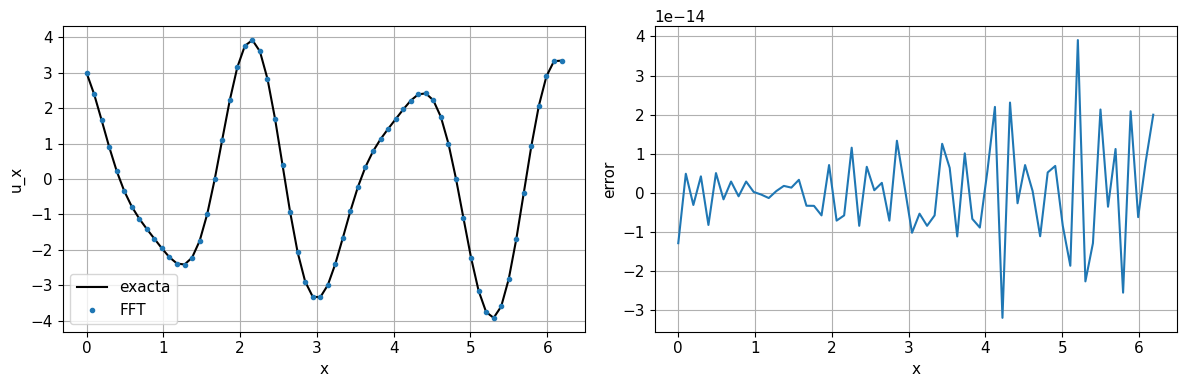

In [2]:
def spectral_derivative(values,L,order=1):
    n=len(values); k=2*np.pi*np.fft.fftfreq(n,d=L/n)
    multiplier=(1j*k)**order
    if n%2==0 and order%2: multiplier[n//2]=0.
    return np.fft.ifft(multiplier*np.fft.fft(values)).real

L=2*np.pi; n=64; x=np.arange(n)*L/n
u=np.sin(3*x)+0.2*np.cos(5*x)
exact=3*np.cos(3*x)-np.sin(5*x)
derivative=spectral_derivative(u,L)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x,exact,"k",label="exacta"); ax[0].plot(x,derivative,"o",markersize=3,label="FFT")
ax[0].set(xlabel="x",ylabel="u_x"); ax[0].legend()
ax[1].plot(x,derivative-exact); ax[1].set(xlabel="x",ylabel="error")
plt.tight_layout(); plt.show()
print("Error máximo:",np.max(abs(derivative-exact)))

**Interpretación del experimento.** Un polinomio trigonométrico resuelto en la malla se deriva casi a precisión de máquina. El ejemplo valida factores, orden de frecuencias y normalización, pero no mide convergencia de un campo con infinitos modos.

## 3. Convergencia para una función analítica

La función $u=e^{\sin x}$ es suave y periódica y tiene infinitos modos. Su derivada es $u_x=e^{\sin x}\cos x$. Comparamos la derivada espectral con la central periódica de segundo orden.

Para funciones analíticas, coeficientes Fourier decaen exponencialmente y la aproximación puede converger geométricamente hasta alcanzar redondeo. Si la función tiene solo regularidad finita, el decaimiento suele ser algebraico. La expresión «precisión espectral» no significa exactitud para cualquier dato.

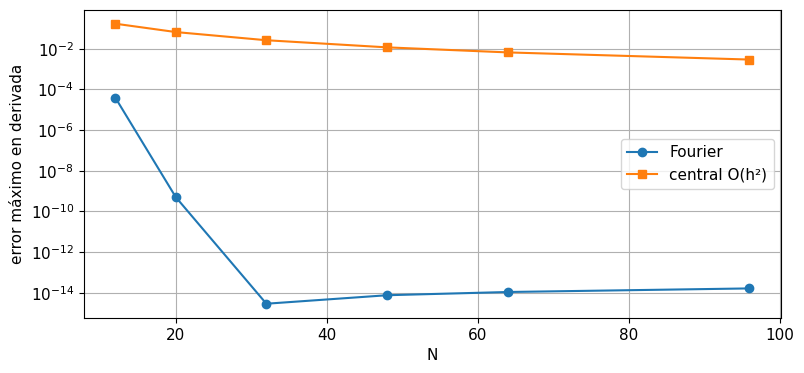

In [3]:
ns=np.array([12,20,32,48,64,96]); spectral_errors=[]; finite_errors=[]
for n in ns:
    dx=2*np.pi/n; x=np.arange(n)*dx; u=np.exp(np.sin(x)); exact=u*np.cos(x)
    ds=spectral_derivative(u,2*np.pi)
    df=(np.roll(u,-1)-np.roll(u,1))/(2*dx)
    spectral_errors.append(np.max(abs(ds-exact))); finite_errors.append(np.max(abs(df-exact)))
plt.semilogy(ns,spectral_errors,"o-",label="Fourier")
plt.semilogy(ns,finite_errors,"s-",label="central O(h²)")
plt.xlabel("N"); plt.ylabel("error máximo en derivada"); plt.legend(); plt.show()

**Interpretación del experimento.** Fourier reduce el error rápidamente mientras que la diferencia central mejora a ritmo algebraico. Cerca de redondeo, añadir modos puede dejar de ayudar e incluso amplificar ruido de evaluación al derivar.

## 4. Difusión diagonal en Fourier

Para $u_t=\alpha u_{xx}$ periódico, cada modo satisface una ODE independiente
$$\widehat u_k'(t)=-\alpha\kappa_k^2\widehat u_k(t),\qquad
\widehat u_k(t)=e^{-\alpha\kappa_k^2t}\widehat u_k(0).$$
Podemos integrar exactamente en tiempo esos modos. Esto elimina el error temporal para la PDE lineal proyectada; permanece el error de representación espacial del dato inicial. El modo cero permanece fijo y representa la media, así que la masa se conserva.

t=0.0, promedio=1.000000000000
t=0.1, promedio=1.000000000000
t=0.5, promedio=1.000000000000
t=2.0, promedio=1.000000000000


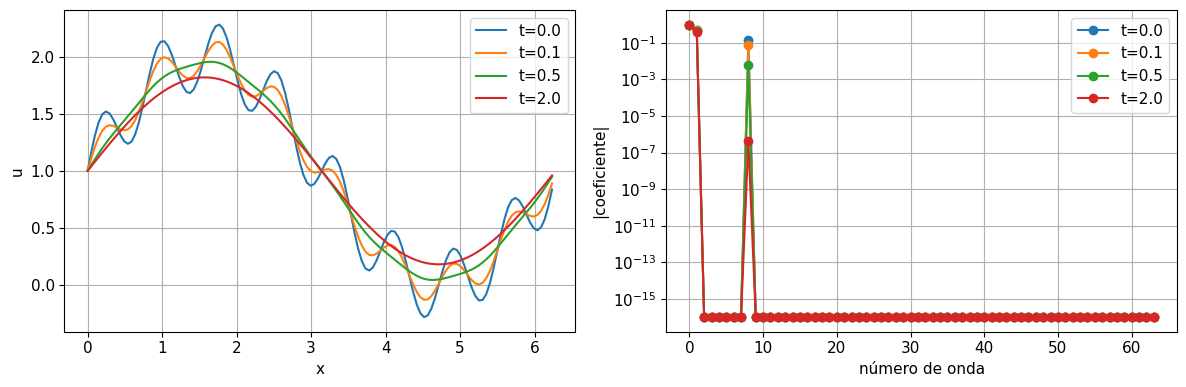

In [4]:
L=2*np.pi; n=128; x=np.arange(n)*L/n; alpha=0.1
u0=1+np.sin(x)+0.3*np.sin(8*x); coefficients=np.fft.fft(u0)
k=2*np.pi*np.fft.fftfreq(n,d=L/n)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for t in [0.,0.1,0.5,2.]:
    transformed=coefficients*np.exp(-alpha*k*k*t)
    u=np.fft.ifft(transformed).real
    ax[0].plot(x,u,label=f"t={t}")
    nonnegative=k>=0
    ax[1].semilogy(k[nonnegative],np.maximum(abs(transformed[nonnegative])/n,1e-16),"o-",label=f"t={t}")
    print(f"t={t}, promedio={u.mean():.12f}")
ax[0].set(xlabel="x",ylabel="u"); ax[1].set(xlabel="número de onda",ylabel="|coeficiente|")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

**Interpretación del experimento.** El modo de frecuencia ocho decae mucho más rápido y la media queda en uno. La figura espectral muestra directamente el mecanismo físico que en espacio se ve como suavizado.

## 5. Poisson periódico y modo cero

Para $-u_{xx}=f$ periódico, $\widehat u_k=\widehat f_k/\kappa_k^2$ cuando $k\ne0$. Para $k=0$, el operador vale cero: la fuente debe tener media cero y la solución queda libre hasta una constante.

Imponemos media de u igual a cero y tomamos $f=\sin3x+\cos2x$, cuya solución es $u=\sin3x/9+\cos2x/4$. No debemos dividir el modo cero por cero ni esconder una fuente incompatible eliminándolo sin explicar la modificación del problema.

Media fuente/solución: -9.627715291671279e-17 -4.0115480381963664e-18 error: 3.469446951953614e-16


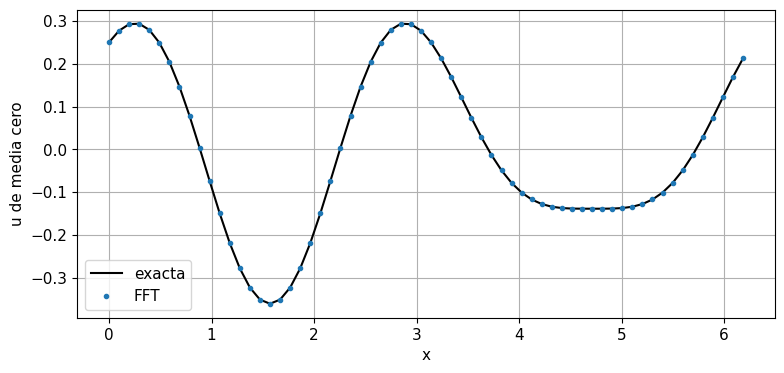

In [5]:
n=64; L=2*np.pi; x=np.arange(n)*L/n; f=np.sin(3*x)+np.cos(2*x)
k=2*np.pi*np.fft.fftfreq(n,d=L/n); fhat=np.fft.fft(f)
if abs(f.mean())>1e-12: raise ValueError("Fuente incompatible con Poisson periódico")
uhat=np.zeros(n,dtype=complex); mask=k!=0
uhat[mask]=fhat[mask]/k[mask]**2
u=np.fft.ifft(uhat).real; exact=np.sin(3*x)/9+np.cos(2*x)/4
plt.plot(x,exact,"k",label="exacta"); plt.plot(x,u,"o",markersize=3,label="FFT")
plt.xlabel("x"); plt.ylabel("u de media cero"); plt.legend(); plt.show()
print("Media fuente/solución:",f.mean(),u.mean(),"error:",np.max(abs(u-exact)))

**Interpretación del experimento.** La solución coincide casi a precisión de máquina porque todos los modos presentes están resueltos. El valor medio se impone como condición adicional; la PDE por sí sola no lo determina.

## 6. Gibbs y discontinuidades

Una serie truncada de un escalón produce oscilaciones cerca del salto. La región afectada se estrecha al añadir modos, pero el sobrepaso máximo no desaparece: es el fenómeno de Gibbs. Puede mejorar error L2 sin converger uniformemente en el salto.

Derivar espectralmente un salto no produce una derivada clásica ordinaria. Filtrar modos suaviza oscilaciones pero altera el campo y puede ensanchar el frente. Debe describirse como una decisión de regularización o modelado.

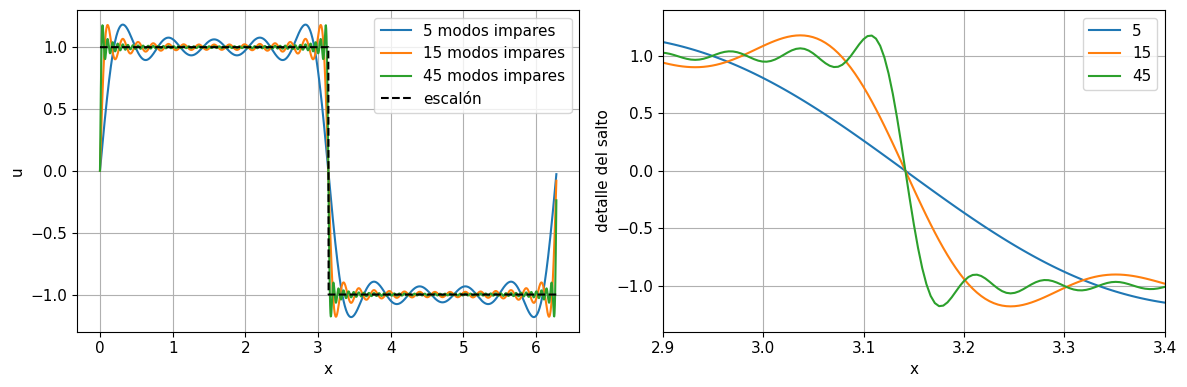

In [6]:
q=np.linspace(0,2*np.pi,1500,endpoint=False)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for modes in [5,15,45]:
    odd=np.arange(1,2*modes,2)
    series=(4/np.pi)*(np.sin(q[:,None]*odd)/odd).sum(axis=1)
    ax[0].plot(q,series,label=f"{modes} modos impares")
    ax[1].plot(q,series,label=f"{modes}")
ax[0].plot(q,np.where(np.sin(q)>=0,1.,-1.),"k--",label="escalón")
ax[0].set(xlabel="x",ylabel="u"); ax[0].legend()
ax[1].set(xlim=(2.9,3.4),ylim=(-1.4,1.4),xlabel="x",ylabel="detalle del salto")
ax[1].legend(); plt.tight_layout(); plt.show()

**Interpretación del experimento.** La oscilación se concentra cada vez más cerca del salto, pero el máximo permanece cerca de un porcentaje fijo de la altura del salto. Juzgar solo un promedio puede ocultar sobrepasos físicamente inadmisibles.

## 7. Aliasing al multiplicar campos

Con N muestras solo se distinguen frecuencias hasta Nyquist. En un producto no lineal, dos modos resueltos generan frecuencias más altas; las no representables pueden plegarse a frecuencias bajas. Esto es aliasing.

Con N=32 y u=sin(10x), el cuadrado contiene modo 20, que no cabe en la malla. Aparece falsamente como modo 12. Una estrategia de desaliasing 2/3 conserva solo el conjunto inferior de modos para operar con no linealidades cuadráticas, filtrando entradas y salida según la convención y los extremos. Otra estrategia rellena de ceros antes del producto y trunca después.

En este caso filtramos el producto a |k|≤10: elimina el modo espurio 12 y conserva el promedio 1/2. El resultado representa una proyección, no todos los detalles del cuadrado continuo.

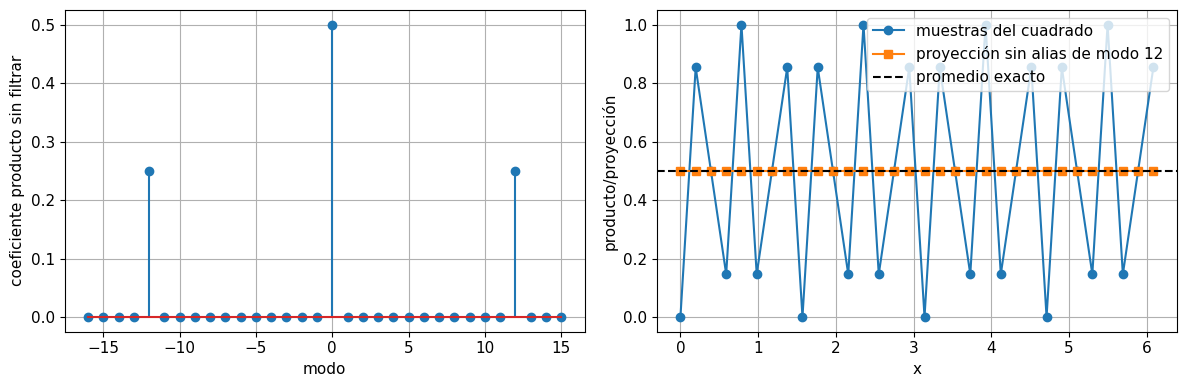

In [7]:
n=32; x=np.arange(n)*2*np.pi/n; mode=np.fft.fftfreq(n,d=1/n)
u=np.sin(10*x); product=u*u; raw=np.fft.fft(product)/n
filtered=raw.copy(); filtered[abs(mode)>n/3]=0.
dealiased=np.fft.ifft(filtered*n).real
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].stem(mode,abs(raw)); ax[0].set(xlabel="modo",ylabel="coeficiente producto sin filtrar")
ax[1].plot(x,product,"o-",label="muestras del cuadrado")
ax[1].plot(x,dealiased,"s-",label="proyección sin alias de modo 12")
ax[1].axhline(0.5,color="k",linestyle="--",label="promedio exacto")
ax[1].set(xlabel="x",ylabel="producto/proyección"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación del experimento.** El promedio es correcto aun cuando aparece una frecuencia falsa. Desaliasing modifica la representación disponible, pero no recupera por magia el modo 20 en una malla incapaz de representarlo. Para conservarlo necesitas más resolución.

## 8. Chebyshev en un intervalo no periódico

Para problemas en $[-1,1]$ sin periodicidad se usan polinomios de Chebyshev $T_k(x)=\cos(k\arccos x)$ y nodos de Lobatto $x_j=\cos(j\pi/N)$. Se concentran cerca de extremos, mitigando oscilaciones de interpolación polinómica.

Una matriz de derivación baricéntrica tiene elementos, para $i\ne j$,
$$D_{ij}=\frac{w_j}{w_i(x_i-x_j)},\qquad D_{ii}=-\sum_{j\ne i}D_{ij},$$
con pesos alternantes y extremos de mitad de magnitud. La suma de cada fila es cero, por lo que deriva exactamente constantes en aritmética ideal. Esta matriz es densa, diferente de un stencil local.

Derivada constante max: 5.051514762044462e-15
Error exp: 6.17284001691587e-14


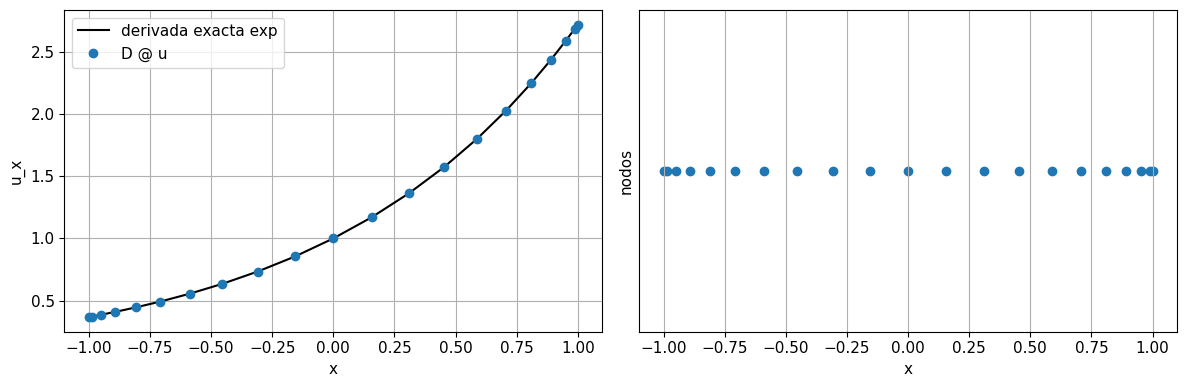

In [8]:
def chebyshev_matrix(n):
    x=np.cos(np.pi*np.arange(n+1)/n)
    weights=(-1.)**np.arange(n+1); weights[[0,-1]]*=0.5
    differences=x[:,None]-x[None,:]
    np.fill_diagonal(differences,1.)
    D=(weights[None,:]/weights[:,None])/differences
    np.fill_diagonal(D,0.); np.fill_diagonal(D,-D.sum(axis=1))
    return x,D

x,D=chebyshev_matrix(20); u=np.exp(x); derivative=D@u
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x,np.exp(x),"k",label="derivada exacta exp")
ax[0].plot(x,derivative,"o",label="D @ u"); ax[0].legend()
ax[0].set(xlabel="x",ylabel="u_x")
ax[1].scatter(x,np.zeros_like(x)); ax[1].set(xlabel="x",ylabel="nodos",yticks=[])
plt.tight_layout(); plt.show()
print("Derivada constante max:",np.max(abs(D@np.ones_like(x))))
print("Error exp:",np.max(abs(derivative-np.exp(x))))

**Interpretación del experimento.** Los nodos aparecen en orden descendente; no se deben ordenar sin reorganizar también D. La densidad de la matriz refleja la base global. La identidad sobre constantes verifica la construcción de la diagonal.

## 9. Poisson con Chebyshev y Dirichlet

Para $-u''=\pi^2\sin(\pi x)$ en $[-1,1]$ con extremos cero, la solución es $\sin(\pi x)$. Formamos $-D^2$, eliminamos extremos fijados y resolvemos para valores interiores.

La matriz es pequeña y densa, por lo que NumPy puede resolverla directamente. En grados muy altos aumenta condicionamiento: más nodos no siempre mejoran precisión después de alcanzar redondeo. Para ecuaciones más complejas se emplean formulaciones espectrales y precondicionamiento especializados.

Error máximo nodal: 3.219646771412954e-15


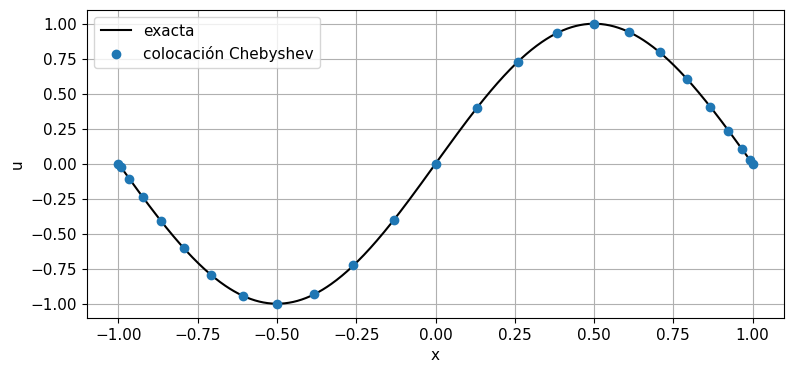

In [9]:
x,D=chebyshev_matrix(24); A=-(D@D)
u=np.zeros_like(x); u[1:-1]=np.linalg.solve(A[1:-1,1:-1],np.pi**2*np.sin(np.pi*x[1:-1]))
q=np.linspace(-1,1,600)
plt.plot(q,np.sin(np.pi*q),"k",label="exacta")
plt.plot(x,u,"o",label="colocación Chebyshev")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()
print("Error máximo nodal:",np.max(abs(u-np.sin(np.pi*x))))

**Interpretación del experimento.** La precisión alta se obtiene con pocos nodos porque la solución es analítica. No se usa FFT periódica para imponer estas fronteras: la base Chebyshev está adaptada a un intervalo con extremos distintos.

## 10. Tiempo, rigidez y coste

Los autovalores de derivadas altas crecen rápidamente con el modo máximo. Integrar difusión con Euler explícito aun después de discretizar espectralmente introduce una restricción de paso severa. El ejemplo lineal exacto evita esa restricción mediante el exponencial modal, pero términos no lineales requieren otros integradores.

Métodos exponenciales, división de operadores e IMEX tratan de manera distinta partes rígidas y no rígidas. La alta precisión espacial no elimina error temporal. Para estudiar convergencia, separa número de modos, paso o tolerancia temporal, y aliasing.

## 11. Neural operators y representación espectral

Una Fourier Neural Operator transforma un campo, aplica operaciones sobre coeficientes Fourier y regresa al espacio físico. Su motivación comparte la representación modal, pero los pesos aprendidos no son automáticamente el operador exacto de una PDE.

Truncar modos limita información de alta frecuencia. Transferir a una malla más fina permite evaluar más puntos, pero no garantiza recuperar detalles ausentes en entrenamiento. Fronteras no periódicas, cambios de geometría y discontinuidades requieren tratamientos explícitos. Compara errores por banda de frecuencia y por observable, además de una norma global.

## 12. Verificación, validación y vínculo con SciML

Una **verificación** pregunta si resolvemos correctamente las ecuaciones que elegimos: compara soluciones exactas, realiza refinamiento de malla, mide residual y observa propiedades discretas. Una **validación física** compara el modelo con mediciones independientes y sus incertidumbres. Un método espectral puede estar perfectamente verificado y aun así representar una ley física inadecuada.

Para fabricar una solución conocida, elige $u_*$, sustitúyela en la PDE y deriva la fuente y las fronteras correspondientes. Al ejecutar el solver, compara con $u_*$ en una norma definida. Este método detecta signos, índices y condiciones de frontera mal implementados; no prueba por sí solo desempeño en todo problema.

Si los campos numéricos se usan para entrenar un operador neuronal, documenta malla, paso temporal, condiciones de frontera, precisión del solver y distribución de parámetros. Reserva casos de prueba y compara también resoluciones no vistas. Un modelo aprendido puede reproducir el sesgo de discretización de sus etiquetas; una métrica sobre la misma malla no revela necesariamente ese problema.

Una PINN utiliza residuales de una PDE, pero también necesita satisfacer datos iniciales y de frontera. Un residual pequeño en pocos puntos no garantiza un campo preciso entre ellos. Compara contra una solución numérica refinada, revisa balances y calcula una norma sobre una malla de evaluación independiente. Las distintas formulaciones de residual, fuerte e integral, aportan criterios científicos diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_3_Finite_Volume_Method.ipynb) | [⏩](../10_OPTIMIZACION/10_1_Optimizacion_matematica.ipynb) |